<a href="https://colab.research.google.com/github/Pavlenko-Kateryna/da_course/blob/main/HW_16_1_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D0%BE%D1%80%D0%B5%D0%BD%D0%B4%D0%BD%D0%BE%D1%97_%D0%BF%D0%BB%D0%B0%D1%82%D0%B8_%D0%B7%D0%B0_%D0%B6%D0%B8%D1%82%D0%BB%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Прогнозування орендної плати за житло

## Мета завдання
Застосувати знання з лекції для побудови моделі лінійної регресії, що прогнозує орендну плату за житло в Індії. Ви пройдете весь цикл вирішення задачі машинного навчання: від дослідницького аналізу до оцінки якості моделі.

## Опис датасету
**House Rent Prediction Dataset** містить інформацію про 4700+ оголошень про оренду житла в Індії з такими параметрами:
- **BHK**: Кількість спалень, залів, кухонь
- **Rent**: Орендна плата (цільова змінна)
- **Size**: Площа в квадратних футах
- **Floor**: Поверх та загальна кількість поверхів
- **Area Type**: Тип розрахунку площі
- **Area Locality**: Район
- **City**: Місто
- **Furnishing Status**: Стан меблювання
- **Tenant Preferred**: Тип орендаря
- **Bathroom**: Кількість ванних кімнат
- **Point of Contact**: Контактна особа

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `House_Rent_Dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (включно з типами даних та кількістю значень)


In [6]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/House_Rent_Dataset.csv")
df.shape

(4746, 12)

In [7]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [9]:
df.dtypes

,0
Posted On,object
BHK,int64
Rent,int64
Size,int64
Floor,object
Area Type,object
Area Locality,object
City,object
Furnishing Status,object
Tenant Preferred,object


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


## Завдання 2: Дослідницький аналіз даних (EDA) (5 балів)

**Що потрібно зробити:**
1. **Аналіз пропущених значень.** Перевірте наявність і відсоток пропущених значень у кожній колонці
2. **Базова статистика.** Обчисліть базову статистику (середнє, квартилі, стандартне відхилення) для числових змінних.
3. **Аналіз цільової змінної.** Побудуйте гістограму розподілу цільової змінної (Rent)
4. **Робота з викидами.** Знайдіть та видаліть викиди в цільовій змінній (якщо є). Визначити викиди можна будь-яким зрозумілим для вас способом, як варіант - таким, що використовується в побудові box-plot (https://en.wikipedia.org/wiki/Box_plot#Example_with_outliers).
5. **Аналіз категоріальних змінних.** Виведіть кількість унікальних значень для кожної з категоріальних колонок.


In [16]:
df.isnull().sum()

,0
Posted On,0
BHK,0
Rent,0
Size,0
Floor,0
Area Type,0
Area Locality,0
City,0
Furnishing Status,0
Tenant Preferred,0


In [17]:
(df.isnull().sum() / len(df)) * 100

,0
Posted On,0.0
BHK,0.0
Rent,0.0
Size,0.0
Floor,0.0
Area Type,0.0
Area Locality,0.0
City,0.0
Furnishing Status,0.0
Tenant Preferred,0.0


In [18]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.746000e+03,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866
std,0.832256,7.810641e+04,634.202328,0.884532
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


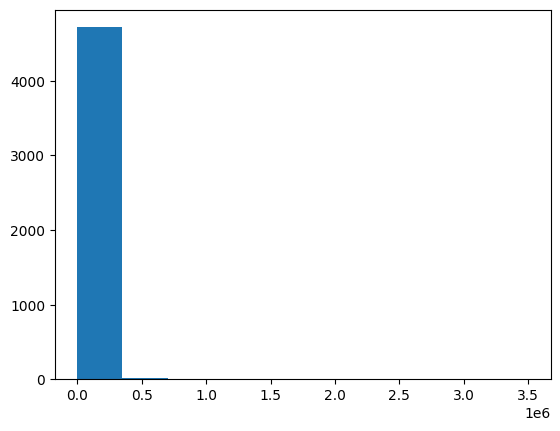

In [25]:
import matplotlib.pyplot as plt
plt.hist(x=df.Rent,bins=10)
plt.show()

Здебільшого дані знаходяться у проміжку 0.0 до 0.25 (до 250000). Прологарифмуємо значення для створення більш нормального розподілу, адже цей скошений вправо.

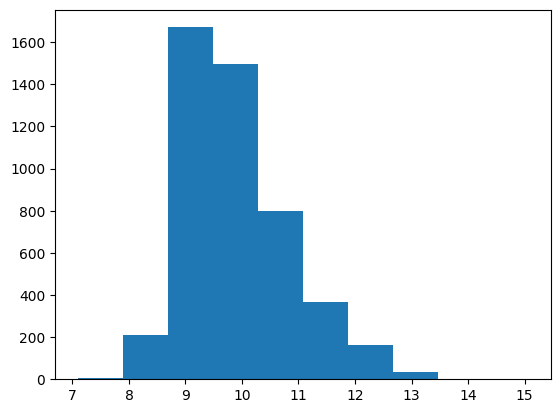

In [23]:
import numpy as np
import matplotlib.pyplot as plt
plt.hist(x=np.log(df.Rent),bins=10)
plt.show()

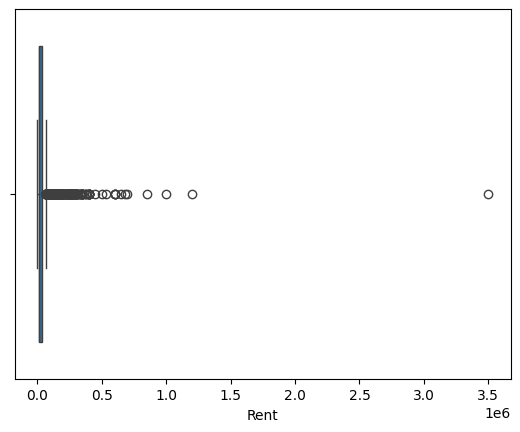

In [29]:
import seaborn as sns
sns.boxplot(data=df,x=df.Rent)
plt.show()

In [33]:
rent_sorted = df.Rent.sort_values()
rent_sorted

,Rent
4076,1200
285,1500
471,1800
2475,2000
146,2200
...,...
1459,700000
1329,850000
827,1000000
1001,1200000


На графіку можемо побачити, що викиди є (особливо 3.5 1e6 значення). Проаналізуємо детальніше

In [34]:
Q1 = rent_sorted.quantile(0.25)
Q3 = rent_sorted.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Нижня межа:", lower_bound)
print("Верхня межа:", upper_bound)

Нижня межа: -24500.0
Верхня межа: 67500.0


Знайдемо кількість викидів за дані межі і видалимо їх

In [41]:
outliers = df[(df.Rent < lower_bound) | (df.Rent > upper_bound)]
print("Кількість викидів: ", len(outliers))
print(outliers.Rent.sort_values(ascending=False))

Кількість викидів:  520
1837    3500000
1001    1200000
827     1000000
1329     850000
1459     700000
         ...   
558       68000
1012      68000
967       68000
2843      68000
642       68000
Name: Rent, Length: 520, dtype: int64


In [44]:
df = df[(df.Rent >= lower_bound) & (df.Rent <= upper_bound)]
print("Після видалення: ", df.Rent.size)

Після видалення:  4226


Будуємо boxplot для нових даних

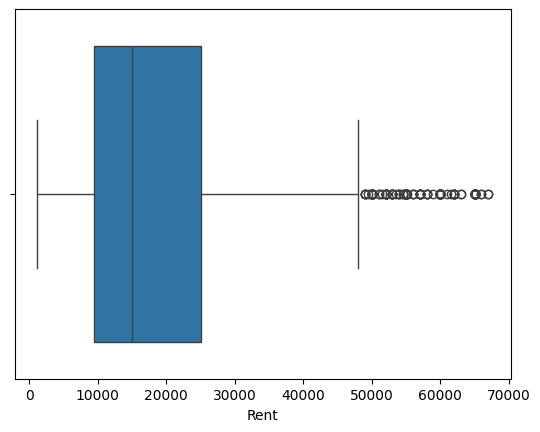

In [45]:
import seaborn as sns
sns.boxplot(data=df,x=df.Rent)
plt.show()

Як бачимо далі після 1 видалення маємо ще декілька "викидів", припускаю, що це дорогі квартири для оренди, тому видаляти не будемо.

In [51]:
df.dtypes

,0
Posted On,object
BHK,int64
Rent,int64
Size,int64
Floor,object
Area Type,object
Area Locality,object
City,object
Furnishing Status,object
Tenant Preferred,object


In [58]:
cat_data = df.select_dtypes(include='object').columns
cat_data

Index(['Posted On', 'Floor', 'Area Type', 'Area Locality', 'City',
       'Furnishing Status', 'Tenant Preferred', 'Point of Contact'],
      dtype='object')

In [60]:
df[cat_data].nunique()

,0
Posted On,80
Floor,340
Area Type,3
Area Locality,1997
City,6
Furnishing Status,3
Tenant Preferred,3
Point of Contact,3



## Завдання 3: Аналіз кореляцій та взаємозв'язків (3 бали)

**Що потрібно зробити:**
1. Обчисліть матрицю кореляцій для числових змінних
2. Візуалізуйте кореляційну матрицю за допомогою heatmap
3. Побудуйте scatter plot між Size та Rent
4. Проаналізуйте взаємозв'язок між BHK та Rent за допомогою boxplot (який розподіл плати для різних значень BHK)


In [61]:
num_data = df.select_dtypes(include='int64').columns
num_data

Index(['BHK', 'Rent', 'Size', 'Bathroom'], dtype='object')

In [68]:
correlation = df[num_data].corr()
correlation

,BHK,Rent,Size,Bathroom
BHK,1.000000,0.401268,0.698453,0.747918
Rent,0.401268,1.000000,0.393605,0.506528
Size,0.698453,0.393605,1.000000,0.680607
Bathroom,0.747918,0.506528,0.680607,1.000000


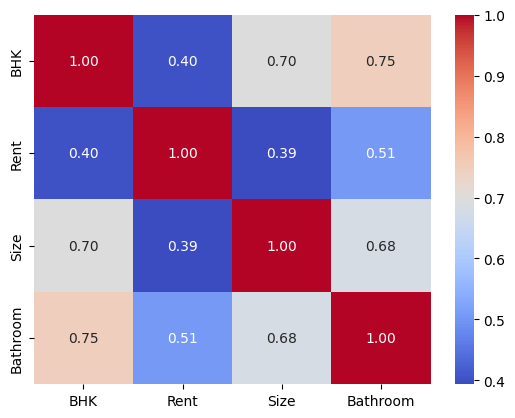

In [70]:
sns.heatmap(correlation,annot=True, fmt=".2f",cmap='coolwarm')
plt.show()

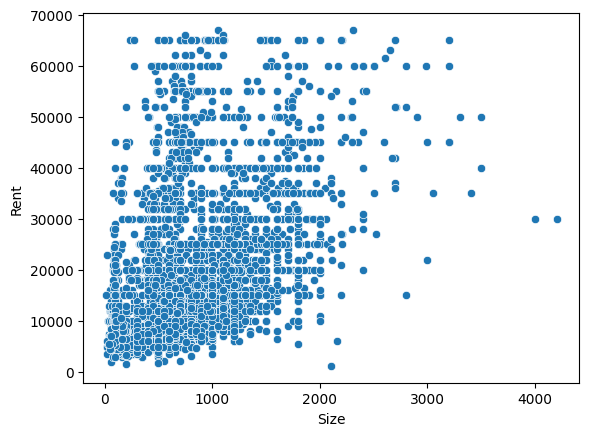

In [75]:
sns.scatterplot(data=df[num_data],x="Size",y="Rent")
plt.show()

## Завдання 4: Feature Engineering та підготовка даних (4 бали)

**Що потрібно зробити:**
1. Закодуйте категоріальні змінні за допомогою One-Hot Encoding. Пригадайте, що в лекції ми говорили щодо кодування кат. змінних з великої кількістю різних значень і як працювати з такими випадками. Ви можете закодувати не всі кат. змінні, а лише ті, що вважаєте за потрібні (скажімо ті, що мають відносно небагато різних значень).
2. **Опціонально (по 0.5 бала за кожну доцільну ознаку):** Додайте нові ознаки, обчислені на основі наявних даних, які б на ваш погляд були корисними для моделі
3. Виберіть ознаки для побудови моделі (виключіть непотрібні колонки). Виключити можна, наприклад, ті колонки, які мають категоріальний тип і забагато (більше 20) різних значень. Треба виключити хоча б 1 колонку.
4. Розділіть дані на ознаки (X) та цільову змінну (y)
5. Застосуйте стандартизацію до числових ознак


In [76]:
df[cat_data].nunique()

,0
Posted On,80
Floor,340
Area Type,3
Area Locality,1997
City,6
Furnishing Status,3
Tenant Preferred,3
Point of Contact,3


Категорії, які мають менше 20 - закодуємо за допомогою OHE. Інші колонки видалимо через велику кількість унікальних значень

In [77]:
cat_cols = ['Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact']

df = pd.get_dummies(df, columns=cat_cols, dtype=int)
df


,Posted On,BHK,Rent,Size,Floor,Area Locality,Bathroom,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,...,City_Mumbai,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
0,2022-05-18,2,10000,1100,Ground out of 2,Bandel,2,0,0,1,...,0,0,0,1,0,1,0,0,0,1
1,2022-05-13,2,20000,800,1 out of 3,"Phool Bagan, Kankurgachi",1,0,0,1,...,0,0,1,0,0,1,0,0,0,1
2,2022-05-16,2,17000,1000,1 out of 3,Salt Lake City Sector 2,1,0,0,1,...,0,0,1,0,0,1,0,0,0,1
3,2022-07-04,2,10000,800,1 out of 2,Dumdum Park,1,0,0,1,...,0,0,0,1,0,1,0,0,0,1
4,2022-05-09,2,7500,850,1 out of 2,South Dum Dum,1,0,1,0,...,0,0,0,1,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2022-05-18,2,15000,1000,3 out of 5,Bandam Kommu,2,0,1,0,...,0,0,1,0,0,1,0,0,0,1
4742,2022-05-15,3,29000,2000,1 out of 4,"Manikonda, Hyderabad",3,0,0,1,...,0,0,1,0,0,1,0,0,0,1
4743,2022-07-10,3,35000,1750,3 out of 5,"Himayath Nagar, NH 7",3,0,1,0,...,0,0,1,0,0,1,0,1,0,0
4744,2022-07-06,3,45000,1500,23 out of 34,Gachibowli,2,0,1,0,...,0,0,1,0,0,0,1,1,0,0


Окремо використаємо регулярний вираз для виокремлення створених колонок

In [79]:
ohe_cols = df.filter(regex='^(Area Type|City|Furnishing Status|Tenant Preferred|Point of Contact)_').columns

df[ohe_cols]

,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,City_Bangalore,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1
1,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,0,1
2,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,0,1
3,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1
4,0,1,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4741,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1
4742,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1
4743,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0
4744,0,1,0,0,0,0,1,0,0,0,1,0,0,0,1,1,0,0


In [92]:
X = df[ohe_cols.to_list() + ["BHK"] + ['Size']]
y = df['Rent']

print(f"\nРозмір X (ознак): {X.shape}")
print(f"Розмір y (цілі): {y.shape}")


Розмір X (ознак): (4226, 20)
Розмір y (цілі): (4226,)


In [93]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_df_scaled =  pd.DataFrame(X_scaled,columns=X.columns, index=X.index)
X_df_scaled

,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area,City_Bangalore,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner,BHK,Size
0,-0.02176,-0.878583,0.879429,-0.502144,-0.501774,-0.387614,-0.499926,2.660884,-0.408755,-0.374584,-0.940704,1.205870,-0.456579,0.597576,-0.315692,-0.577532,-0.015385,0.577897,0.052966,0.469859
1,-0.02176,-0.878583,0.879429,-0.502144,-0.501774,-0.387614,-0.499926,2.660884,-0.408755,-0.374584,1.063034,-0.829277,-0.456579,0.597576,-0.315692,-0.577532,-0.015385,0.577897,0.052966,-0.147778
2,-0.02176,-0.878583,0.879429,-0.502144,-0.501774,-0.387614,-0.499926,2.660884,-0.408755,-0.374584,1.063034,-0.829277,-0.456579,0.597576,-0.315692,-0.577532,-0.015385,0.577897,0.052966,0.263980
3,-0.02176,-0.878583,0.879429,-0.502144,-0.501774,-0.387614,-0.499926,2.660884,-0.408755,-0.374584,-0.940704,1.205870,-0.456579,0.597576,-0.315692,-0.577532,-0.015385,0.577897,0.052966,-0.147778
4,-0.02176,1.138197,-1.137102,-0.502144,-0.501774,-0.387614,-0.499926,2.660884,-0.408755,-0.374584,-0.940704,1.205870,2.190201,-1.673428,-0.315692,-0.577532,-0.015385,0.577897,0.052966,-0.044839
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4741,-0.02176,1.138197,-1.137102,-0.502144,-0.501774,-0.387614,2.000296,-0.375815,-0.408755,-0.374584,1.063034,-0.829277,-0.456579,0.597576,-0.315692,-0.577532,-0.015385,0.577897,0.052966,0.263980
4742,-0.02176,-0.878583,0.879429,-0.502144,-0.501774,-0.387614,2.000296,-0.375815,-0.408755,-0.374584,1.063034,-0.829277,-0.456579,0.597576,-0.315692,-0.577532,-0.015385,0.577897,1.393288,2.322771
4743,-0.02176,1.138197,-1.137102,-0.502144,-0.501774,-0.387614,2.000296,-0.375815,-0.408755,-0.374584,1.063034,-0.829277,-0.456579,0.597576,-0.315692,1.731505,-0.015385,-1.730413,1.393288,1.808073
4744,-0.02176,1.138197,-1.137102,-0.502144,-0.501774,-0.387614,2.000296,-0.375815,-0.408755,-0.374584,1.063034,-0.829277,-0.456579,-1.673428,3.167640,1.731505,-0.015385,-1.730413,1.393288,1.293375


## Завдання 5: Розділення даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на навчальну (80%) та тестову (20%) вибірки.
2. Створіть модель лінійної регресії.
3. Навчіть модель на навчальних даних.
4. Виведіть усі коефіцієнти моделі (ваги) та напишіть, які 2 ознаки найбільше впливають на прогноз.
5. Зробіть прогнози на тренувальній та тестовій вибірках.

In [94]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_df_scaled,y,test_size=0.2,random_state=42)

In [95]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [99]:
for feature, weight in zip(model.feature_names_in_, model.coef_):
  print(f"{feature}: {weight}")

Area Type_Built Area: 45.15349752839379
Area Type_Carpet Area: 58.010079112586936
Area Type_Super Area: -59.98327743767641
City_Bangalore: -820.5429666764775
City_Chennai: -1178.1552353051525
City_Delhi: -34.12413203902787
City_Hyderabad: -1629.6582046492254
City_Kolkata: -1975.3718617622299
City_Mumbai: 6039.121609918993
Furnishing Status_Furnished: 1101.0945911971362
Furnishing Status_Semi-Furnished: -61.313744141599884
Furnishing Status_Unfurnished: -673.8394738050196
Tenant Preferred_Bachelors: 287.4759350981312
Tenant Preferred_Bachelors/Family: 27.061111653840463
Tenant Preferred_Family: -419.8438561970747
Point of Contact_Contact Agent: 1951.4516247255644
Point of Contact_Contact Builder: -29.21307913140495
Point of Contact_Contact Owner: -1949.7998122478396
BHK: 3626.515148360706
Size: 4392.892205192136


Наійбільше впливає розташування квартири у місті, а саме у Мумбаї, і її площа

In [102]:
y_train_pred = model.predict(X_train)

y_test_pred = model.predict(X_test)

compare = pd.DataFrame({
    'Реальна ціна': y_test.values[:10],
    'Прогнозована ціна': y_test_pred[:10],
    'Помилка': (y_test.values[:10] - y_test_pred[:10])

})
print(compare)

   Реальна ціна  Прогнозована ціна      Помилка
0         22000       29558.083050 -7558.083050
1          5000        3581.715372  1418.284628
2         37000       39748.036920 -2748.036920
3          8000        3350.760200  4649.239800
4         15000       15338.594615  -338.594615
5         20000       25076.940817 -5076.940817
6          8500       18172.505927 -9672.505927
7          7000        3579.567365  3420.432635
8          3000        -834.355080  3834.355080
9          8000        6735.472407  1264.527593


## Завдання 6: Оцінка якості моделі (2 бали)

**Що потрібно зробити:**
1. Обчисліть MAE, RMSE та R² для навчальної та тестової вибірок
2. Порівняйте метрики та зробіть висновок про якість моделі
3. Проаналізуйте і дайте висновок, чи є ознаки перенавчання або недонавчання (**Нагадування**: перенавчання - коли модель дуже добре працює на тренувальних даних, але погано на тестових; недонавчання - коли модель погано працює навіть на тренувальних даних)
4. Побудуйте графік розсіювання "реальні vs прогнозовані значення" та зробіть висновок про якість моделі


In [106]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Тестова вибірка
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test, y_test_pred)
print("----- Тестова вибірка -----")
print(f"MAE: {mae_test}")
print(f"RMSE: {rmse_test}")
print(f"R2: {r2_test}")

# Тренувальна вибірка
mae_train = mean_absolute_error(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
rmse_train = np.sqrt(mse_train)
r2_train = r2_score(y_train, y_train_pred)
print("----- Тренувальна вибірка -----")
print(f"MAE: {mae_train}")
print(f"RMSE: {rmse_train}")
print(f"R2: {r2_train}")

----- Тестова вибірка -----
MAE: 5612.876335130387
RMSE: 7852.390996387321
R2: 0.6784209774549648
----- Тренувальна вибірка -----
MAE: 5602.841679476624
RMSE: 7770.4388718809
R2: 0.6837347239575569


Значення метрик мають невелику різницю між собою, тому ознак перенавчання немає. Точність моделі 68%, що є непоганим результатом



In [108]:
import plotly.express as px
import plotly.graph_objects as go
fig = px.scatter(
    x=y_test,
    y=y_test_pred,
    title='Реальні vs Прогнозовані ціна (тестова вибірка)',
    labels={'x': 'Реальна ціна', 'y': 'Прогнозована ціна'},
    opacity=0.6
)

max_val = max(y_test.max(), y_test_pred.max())
fig.add_trace(
    go.Scatter(
        x=[0, max_val],
        y=[0, max_val],
        mode='lines',
        name='Ідеальний прогноз',
        line=dict(color='red', dash='dash')
    )
)

fig.update_layout(height=500)
fig.show()

Як бачимо модель до половини шляху показує гарні результати, трохи далі починає гірше прогнозувати, але певний підйом є, але не на рівні ідеальної прямої

## Завдання 7: Аналіз помилок (4 бали)

**Що потрібно зробити:**
1. Обчисліть помилки (residuals = реальні - прогнозовані значення)
2. Побудуйте гістограму розподілу помилок
3. Створіть scatter plot помилок відносно величини прогнозованих значень. Чи росте помилка з ростом прогнозованого значення?
4. Знайдіть 5 прогнозів з найбільшими помилками
5. Проаналізуйте, на яких типах житла модель помиляється найбільше. Типи можна розрізняти за кількістю кімнат чи містом, наприклад.
6. Подумайте і напишіть, які наступні кроки ви б зробили, аби поліпшити якість моделі. Опціонально можна їх зробити і ми перевіримо :)

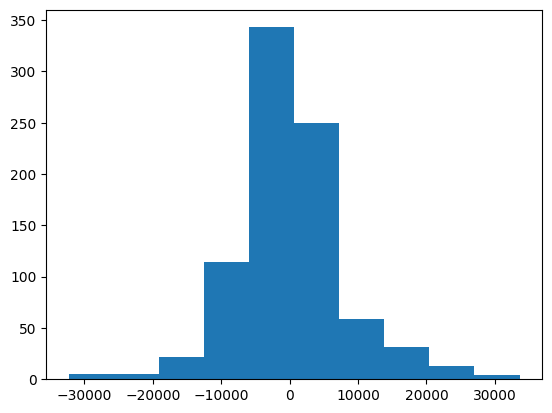

In [110]:
residuals = y_test - y_test_pred

plt.hist(residuals)
plt.show()

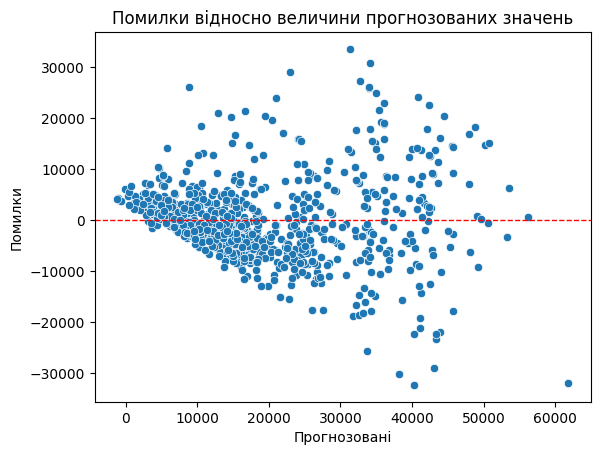

In [114]:
sns.scatterplot(x=y_test_pred,y=residuals)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1)
plt.title("Помилки відносно величини прогнозованих значень")
plt.xlabel("Прогнозовані")
plt.ylabel("Помилки")
plt.show()

Як можемо при збільшенні прогнозованого значення збільшується і помилка, причому у обидві сторони (прогнозування більшого і меншого значення)

In [115]:
errors_df = pd.DataFrame({
    'real': y_test.values,
    'predicted': y_test_pred,
    'error': np.abs(residuals)
})

top = errors_df.nlargest(5, 'error')
print("Ціни з найбільшими похибками у прогнозуванні:")
print(top)

Ціни з найбільшими похибками у прогнозуванні:
       real     predicted         error
3962  65000  31394.533355  33605.466645
549    8000  40306.975898  32306.975898
275   30000  61845.165077  31845.165077
3520  65000  34151.950119  30848.049881
904    8000  38154.065455  30154.065455


Для цього датасету можливо використати інші моделі машинного навчання. Наприклад, поліноміальна регресія або ансамблеві методи (градієнтний бустинг наприклад)